# Heart Disease Prediction System

*Adapted from the Titanic Passenger Survival Prediction System (same teaching structure, same steps), as a machine learning course assignment.*

## Setup: Running This Notebook From Scratch

Run these commands in a terminal, inside this project's folder, before opening the notebook.

```
python -m venv venv                  # 1. create a virtual environment
venv\Scripts\activate.bat           # 2. activate it (Windows CMD)
source venv/bin/activate             #    (macOS / Linux)
pip install -r requirements-notebook.txt   # 3. install the packages (includes Jupyter)
jupyter notebook                     # 4. launch Jupyter, open this file, Kernel -> Restart & Run All
```

Any Python 3.11 - 3.13 should work. Keep `processed.cleveland.data` in the same folder as this notebook.

---

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) from a few clinical attributes.
##### **Application** Learning data science, testing ML algorithms, and understanding which clinical factors are linked to heart disease.

> **Disclaimer:** This is a student learning project. It is **not** a medical tool and must never be used to diagnose anyone.

## Input and Output

### Inputs (Features / Attributes) - only 4 attributes selected from the 13 available

| **Input Attribute** | **Meaning** | **Possible Values** |
| --- | --- | --- |
| **sex** | Sex of the patient | 1 = Male, 0 = Female |
| **cp** | Chest pain type | 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic |
| **exang** | Exercise-induced angina | 1 = Yes, 0 = No |
| **oldpeak** | ST depression induced by exercise relative to rest (a number measured on an exercise ECG) | 0.0 to 6.2 in this dataset |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | 1 = Heart disease present, 0 = No heart disease |

**Why these 4?** I compared every 4-attribute combination using 5-fold cross-validation with the same SVC model. Combinations that use `ca` (vessels seen on fluoroscopy) and `thal` (thallium stress-test result) score higher (about 0.82 - 0.85), but those need specialised hospital tests and have a few missing values, which makes them impractical for a simple web form. Among the remaining attributes, `sex + cp + exang + oldpeak` scored best (about 0.79). All four are already numeric, so no encoding is needed.

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | *<your name>* |
| **Roll Number** | *<your roll number>* |
| **Course / Instructor** | Machine Learning / *<instructor name>* |
| **Program Name** | heart_disease_project |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3.12 |
| **Libraries** | NumPy, Pandas, Pickle (built-in), scikit-learn 1.8.0, Matplotlib, Seaborn, Streamlit |
| **Dataset** | UCI Heart Disease Data Set - Cleveland subset (`processed.cleveland.data`, 303 patients) |
| **Live App** | *<paste your streamlit.app link here after deploying>* |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction (select the 4 input attributes)
- Step 5: Label Encoding - **not required** (all attributes are already numeric)
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries needed to load data, train a Support Vector Classifier
(SVC), evaluate it and plot the results.
"""

# Numerical computing (arrays, math operations)
import numpy as np

# Data manipulation (DataFrames, reading/writing CSV files)
import pandas as pd

# Saving and loading the trained model
import pickle

# Dividing the dataset into training and testing sets
from sklearn.model_selection import train_test_split, cross_val_score

# Support Vector Machine (SVM) model
from sklearn import svm

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Plotting (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

# NOTE: LabelEncoder is intentionally NOT imported - this dataset is already numeric.

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
Loads the Cleveland heart disease data into a pandas DataFrame.
The raw file has no header row, so we supply the 14 column names ourselves
(taken from heart-disease.names). Missing values are written as '?' in the
file, so we tell pandas to treat '?' as NaN.
"""

column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

raw_data = pd.read_csv("processed.cleveland.data", header=None,
                       names=column_names, na_values="?")

print("\n\nRaw Sample Data (first 10 rows):")
print("================================\n")
pd.set_option("display.max_columns", None)
print(raw_data.head(10))



Raw Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
1. Print the attribute (column) names.
2. Show the number of instances (rows).
3. Show how the output attribute 'num' is distributed.
4. Show which columns have missing values.
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(raw_data.columns))

print("\n\nNumber of Instances in Sample Data:", raw_data["age"].count())
print("====================================\n")

print("Distribution of 'num' (0 = no disease, 1-4 = disease of increasing severity):")
print(raw_data["num"].value_counts().sort_index())

print("\n\nMissing values per column (only columns that have any):")
print("========================================================\n")
missing = raw_data.isna().sum()
print(missing[missing > 0])



Attributes in Sample Data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


Number of Instances in Sample Data: 303

Distribution of 'num' (0 = no disease, 1-4 = disease of increasing severity):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


Missing values per column (only columns that have any):

ca      4
thal    2
dtype: int64


#### Step 3.2: Pre-process Sample Data

In [4]:
"""
Purpose of this section:
-------------------------
The original 'num' attribute has 5 values (0 to 4). Following the standard
use of this dataset, we simplify it into a binary output:
    0       -> no heart disease
    1,2,3,4 -> heart disease present  (becomes 1)
The new output attribute is called 'HeartDisease'.

(The only columns with missing values - 'ca' and 'thal' - are not among our
4 selected inputs, so no rows need to be removed or filled.)
"""

raw_data["HeartDisease"] = (raw_data["num"] > 0).astype(int)

print("\n\nHeartDisease Attribute (0 = No, 1 = Yes):")
print("=========================================\n")
print(raw_data["HeartDisease"].value_counts().sort_index())



HeartDisease Attribute (0 = No, 1 = Yes):

HeartDisease
0    164
1    139
Name: count, dtype: int64


### Step 4: Feature Extraction
We select only **4 input attributes** (`sex`, `cp`, `exang`, `oldpeak`) plus the output attribute `HeartDisease`.

In [5]:
"""
Purpose of this section:
-------------------------
Keeps only the 4 chosen input attributes and the output attribute, and saves
the result as 'sample-data.csv' (the equivalent of the Titanic sample-data.csv).
The output attribute is placed in the LAST column, which the training steps
below rely on.
"""

selected_inputs = ["sex", "cp", "exang", "oldpeak"]

sample_data = raw_data[selected_inputs + ["HeartDisease"]].copy()
sample_data["sex"] = sample_data["sex"].astype(int)
sample_data["cp"] = sample_data["cp"].astype(int)
sample_data["exang"] = sample_data["exang"].astype(int)

sample_data.to_csv("sample-data.csv", index=False, header=True)

print("\n\nSample Data after Feature Extraction:")
print("=====================================\n")
print(sample_data.head(10))
print("\nShape:", sample_data.shape)
print("Missing values in selected columns:", int(sample_data.isna().sum().sum()))
print("\nSaved: sample-data.csv")



Sample Data after Feature Extraction:

   sex  cp  exang  oldpeak  HeartDisease
0    1   1      0      2.3             0
1    1   4      1      1.5             1
2    1   4      1      2.6             1
3    1   3      0      3.5             0
4    0   2      0      1.4             0
5    1   2      0      0.8             0
6    0   4      0      3.6             1
7    0   4      1      0.6             0
8    1   4      0      1.4             1
9    1   4      1      3.1             1

Shape: (303, 5)
Missing values in selected columns: 0

Saved: sample-data.csv


### Step 5: Label Encoding the Sample Data

**Not required.** `sex`, `cp`, `exang` and `oldpeak` are already stored as numbers, and `HeartDisease` is already 0/1. The SVC can use them directly, so no `LabelEncoder` is used anywhere in this project (including the web app).

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [6]:
"""
Purpose of this section:
-------------------------
Splits the data into 80% Training Data and 20% Testing Data.
- random_state=0 makes the split reproducible.
- Unlike the small Titanic file (already in random order), we let the split
  shuffle the rows, and use stratify so both sets keep the same share of
  patients with / without heart disease.
"""

training_data, testing_data = train_test_split(
    sample_data,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data["HeartDisease"]
)

training_data.to_csv("training-data.csv", index=False, header=True)
testing_data.to_csv("testing-data.csv", index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [7]:
# Input vectors = all columns except the last; output label = the last column
input_vector_train = training_data.iloc[:, :-1]
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [8]:
"""
Purpose of this section:
-------------------------
Trains a Support Vector Classifier (SVC) - the same model and parameters as
the Titanic notebook.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma='auto', random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [9]:
# Save the trained model so it can be reused (and deployed) without retraining
with open("svc_trained_model.pkl", "wb") as f:
    pickle.dump(svc_model, f)
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [10]:
input_vector_test = testing_data.iloc[:, :-1]
output_label_test = testing_data.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [11]:
with open("svc_trained_model.pkl", "rb") as f:
    model = pickle.load(f)
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model
##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [12]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data["Predictions"] = model_predictions
testing_data.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions.head(15))



Predictions Returned by svc_trained_model:

     sex  cp  exang  oldpeak  HeartDisease  Predictions
125    0   2      0      0.6             0            0
83     1   3      1      1.6             1            1
53     1   2      0      0.0             0            0
45     1   3      0      2.5             1            1
248    1   4      0      1.0             1            1
211    1   1      1      3.8             1            0
36     1   4      1      2.5             1            1
106    1   4      1      0.0             1            1
120    1   4      1      0.0             1            1
31     1   4      1      1.4             1            1
156    1   4      1      1.6             1            1
157    1   4      0      0.0             1            0
148    1   2      0      0.0             0            0
253    0   3      0      0.6             0            0
250    1   4      1      1.5             0            1


#### Step 7.4: Calculate the Accuracy Score

In [13]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.84


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.79      0.94      0.86        33
   Heart Disease (1)       0.91      0.71      0.80        28

            accuracy                           0.84        61
           macro avg       0.85      0.83      0.83        61
        weighted avg       0.85      0.84      0.83        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     31                   2
Actual: Disease                         8                  20


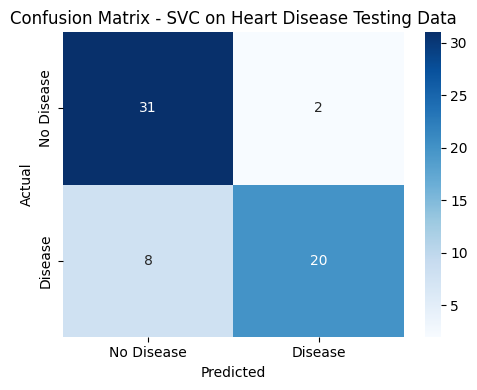

In [14]:
"""
Accuracy alone can hide problems, so we also report:
- Precision: of the patients predicted to HAVE heart disease, how many really do?
- Recall:    of the patients who really HAVE heart disease, how many did we catch?
- F1-score:  harmonic mean of precision and recall.
- Confusion Matrix: correct vs. incorrect predictions per class.
For a health problem, recall on the "Heart Disease" class matters a lot -
a missed case (false negative) is worse than a false alarm.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

#### Step 7.6: Cross-Validation Check (extra)

In [15]:
"""
The testing set has only ~61 patients, so one lucky or unlucky split can move
the accuracy by several points. 5-fold cross-validation trains and tests the
model 5 times on different splits of the whole dataset and gives a steadier
estimate of real performance.
"""

cv_scores = cross_val_score(svm.SVC(gamma='auto', random_state=0),
                            sample_data.iloc[:, :-1], sample_data.iloc[:, -1], cv=5)

print("5-fold cross-validation accuracies:", np.round(cv_scores, 2))
print("Mean cross-validation accuracy    :", round(cv_scores.mean(), 2))

5-fold cross-validation accuracies: [0.72 0.87 0.8  0.78 0.77]
Mean cross-validation accuracy    : 0.79


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
"""
Purpose of this section:
-------------------------
Takes the 4 input values for ONE new patient. A demo patient is pre-filled so
the notebook runs top-to-bottom without typing. To enter your own values,
replace the four lines below with:

    sex_input   = int(input("Sex (1 = Male, 0 = Female): "))
    cp_input    = int(input("Chest pain type (1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal, 4 = Asymptomatic): "))
    exang_input = int(input("Exercise-induced angina (1 = Yes, 0 = No): "))
    oldpeak_input = float(input("ST depression (oldpeak, e.g. 1.5): "))
"""

sex_input = 1        # Male
cp_input = 4         # Asymptomatic
exang_input = 1      # Yes
oldpeak_input = 2.0  # ST depression

print(f"sex: {sex_input}, cp: {cp_input}, exang: {exang_input}, oldpeak: {oldpeak_input}")

sex: 1, cp: 4, exang: 1, oldpeak: 2.0


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [17]:
user_input = pd.DataFrame({
    "sex": [sex_input],
    "cp": [cp_input],
    "exang": [exang_input],
    "oldpeak": [oldpeak_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   sex  cp  exang  oldpeak
0    1   4      1      2.0


#### Step 8.3: Label Encoding of Feature Vector
**Not required** - the feature vector above is already numeric and has exactly the same columns, in the same order, as the training data. It goes straight to the model.

#### Step 8.4: Load the Saved Model

In [18]:
with open("svc_trained_model.pkl", "rb") as f:
    model = pickle.load(f)
print("Model loaded.")

Model loaded.


#### Step 8.5: Model Prediction
##### Step 8.5.1: Apply Model on the Feature Vector of the unseen instance and return Prediction to the User

In [19]:
predicted_class = model.predict(user_input)[0]

if predicted_class == 1:
    prediction = "HEART DISEASE PRESENT"
else:
    prediction = "NO HEART DISEASE"

print("+" + "-" * 34 + "+")
print("|" + "** Prediction **".center(34) + "|")
print("+" + "-" * 34 + "+")
print("|" + prediction.center(34) + "|")
print("+" + "-" * 34 + "+")

+----------------------------------+
|         ** Prediction **         |
+----------------------------------+
|      HEART DISEASE PRESENT       |
+----------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [20]:
"""
Purpose of this section:
-------------------------
Example feedback (illustrative, written for this assignment - not from real
clinicians) on the model's predictions for a few typical cases.
The "Model said" column is produced live by the trained model.
"""

cases = pd.DataFrame({
    "sex":     [1, 0, 1, 0],
    "cp":      [4, 3, 4, 1],
    "exang":   [1, 0, 0, 0],
    "oldpeak": [2.5, 0.0, 0.0, 0.5],
})
cases["Model said"] = ["Disease" if p == 1 else "No disease" for p in model.predict(cases)]
print(cases.to_string(index=False))

 sex  cp  exang  oldpeak Model said
   1   4      1      2.5    Disease
   0   3      0      0.0 No disease
   1   4      0      0.0 No disease
   0   1      0      0.5 No disease


In [21]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Student Tester", "Domain Expert (Cardiology)"],
    "Case": [
        "Male, asymptomatic chest pain, exercise angina, ST depression 2.5",
        "Female, non-anginal pain, no exercise angina, ST depression 0.0",
        "Any patient - overall model use",
    ],
    "Feedback": [
        "Plausible: exercise-induced angina with ST depression is a recognised warning sign.",
        "Plausible: a low-risk profile on these four attributes.",
        "Four attributes are not enough for a real decision; age, cholesterol, blood pressure and maximum heart rate matter too. Also, a missed case is worse than a false alarm, so recall for the disease class should be improved.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                              Case                                                                                                                                                                                                                     Feedback
Domain Expert (Cardiology) Male, asymptomatic chest pain, exercise angina, ST depression 2.5                                                                                                                                          Plausible: exercise-induced angina with ST depression is a recognised warning sign.
            Student Tester   Female, non-anginal pain, no exercise angina, ST depression 0.0                                                                                                                                                                      Plausible: a low-risk profile on these four attributes.
Domain Expert (Cardiology)                                

#### Step 9.2: Make a List of Potential Improvements

In [22]:
improvements = [
    "The assignment limits the model to 4 inputs; a real system would add age, cholesterol, resting blood pressure and maximum heart rate",
    "Scale the numeric attributes (e.g. StandardScaler) and tune SVC parameters (C, gamma, kernel) with cross-validation",
    "Use more data (e.g. combine the Cleveland, Hungarian, Swiss and VA files) - 303 patients is small",
    "Optimise for recall on the heart-disease class, since missing a sick patient is the costly error",
    "Compare more models (Logistic Regression, Random Forest, Gradient Boosting)",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. The assignment limits the model to 4 inputs; a real system would add age, cholesterol, resting blood pressure and maximum heart rate
2. Scale the numeric attributes (e.g. StandardScaler) and tune SVC parameters (C, gamma, kernel) with cross-validation
3. Use more data (e.g. combine the Cleveland, Hungarian, Swiss and VA files) - 303 patients is small
4. Optimise for recall on the heart-disease class, since missing a sick patient is the costly error
5. Compare more models (Logistic Regression, Random Forest, Gradient Boosting)


#### Step 9.3: Improve the Model Based on Feedback

In [23]:
print("Next version: add more attributes + scaling, tune the model with cross-validation, "
      "then re-run Steps 6-7 and only replace svc_trained_model.pkl if the results improve.")

Next version: add more attributes + scaling, tune the model with cross-validation, then re-run Steps 6-7 and only replace svc_trained_model.pkl if the results improve.


## Step 10: Deploy Your Model as a Public Web App

#### Step 10.1: Why Deploy a Model?
A model that only runs inside your Jupyter notebook helps nobody else. Deploying it as a web app lets anyone use it from a browser with nothing installed.

#### Step 10.2: Create a GitHub Account and Repository
1. Sign up / log in at https://github.com.
2. Click **+ -> New repository**, name it (e.g. `heart-disease-prediction`), set it to **Public**, and create it.
3. Upload the project files (**Add file -> Upload files**). At minimum the repo must contain `app.py`, `requirements.txt` and `svc_trained_model.pkl` **in the root of the repository**.

#### Step 10.3: Write a Simple Web App
`app.py` (included in this project) uses **Streamlit**: it loads the pickled model, collects the 4 inputs with `st.selectbox` / `st.number_input`, calls `model.predict(...)` when the button is clicked and shows the result. No label encoder is needed because the model takes the numeric values directly.

#### Step 10.4: Create a Streamlit Community Cloud Account
Go to https://share.streamlit.io and sign in with GitHub (free for public apps).

#### Step 10.5: Deploy Your App
1. **Create app -> Deploy a public app from GitHub**.
2. Repository: `<your-username>/heart-disease-prediction`, Branch: `main`, Main file path: `app.py`.
3. Open **Advanced settings** and choose Python **3.11** or **3.12**.
4. Click **Deploy**. After a few minutes you get a public link like `https://<something>.streamlit.app`.

#### Step 10.6: Troubleshooting Common Issues
- **`ModuleNotFoundError` / package install fails:** the default Python version may be too new for some packages. In **Manage app -> Settings -> General**, set Python to 3.11 or 3.12 and reboot.
- **`InconsistentVersionWarning` or the model fails to load:** the scikit-learn version in `requirements.txt` must match the one that trained the model (`scikit-learn==1.8.0` here). If you retrain with a different version, update `requirements.txt` to match.
- **`requirements.txt` ignored / app can't find the model:** both files must sit in the same folder as `app.py` (the repo root).
- **Stuck on "in the oven":** click **Manage app**, read the build log for red errors, fix, then reboot.

#### Step 10.7: Share Your Live Link
Paste the link into the "Live App" row above and into `README.md`.

---

## Conclusion
Using only four attributes - sex, chest pain type, exercise-induced angina and ST depression - a Support Vector Classifier can separate patients with and without heart disease clearly better than chance (see the accuracy in Step 7.4 and the more stable cross-validation score in Step 7.6). Chest pain type, exercise angina and ST depression are the attributes most strongly linked to the disease in this data. Because the model sees so little information and the dataset is small (303 patients), it is a teaching demo only and must not be used for real medical decisions.